## PCOS Detection Using Machine Learning


In [ ]:
import pandas as pd              # for data handling & analysis
import numpy as np               # for numerical operations
import matplotlib.pyplot as plt  # for visualizations
import seaborn as sns            # for beautiful statistical plots
import warnings                  # to ignore unnecessary warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("  dataset.csv")

In [ ]:
df.head()

,Patient File No.,Stress_Level,Age,Weight,Height,BMI,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Family_History_PCOS,...,Skin darkening (Y/N),sleep Hours,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),Hair loss(Y/N),Marital_Status,Length_of_cycle,hair growth(Y/N),PCOS (Y/N)
0,1,1,28,44.6,152.0,19.3,78,22,10.48,0,...,0,8.0,0,1.0,0,0,0,27,0,0
1,2,0,36,65.0,161.5,24.9,74,20,11.70,0,...,0,7.5,0,0.0,0,0,0,25,0,0
2,3,1,33,68.8,165.0,25.3,72,18,11.80,1,...,0,5.0,1,1.0,0,1,0,30,0,1
3,4,1,37,65.0,148.0,29.7,72,20,12.00,1,...,0,8.5,0,0.0,0,0,0,28,0,0
4,5,1,25,52.0,161.0,20.1,72,18,10.00,0,...,0,7.5,0,0.0,0,1,0,35,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient File No.        541 non-null    int64  
 1   Stress_Level            541 non-null    int64  
 2    Age                    541 non-null    int64  
 3   Weight                  541 non-null    float64
 4   Height                  541 non-null    float64
 5   BMI                     541 non-null    float64
 6   Pulse rate(bpm)         541 non-null    int64  
 7   RR (breaths/min)        541 non-null    int64  
 8   Hb(g/dl)                541 non-null    float64
 9   Family_History_PCOS     541 non-null    int64  
 10  Thyroid                 541 non-null    int64  
 11  Cycle(R/I)              541 non-null    int64  
 12  menstrual length(days)  541 non-null    int64  
 13  Smoking                 541 non-null    int64  
 14  Hip(inch)               541 non-null    in

In [ ]:
df.describe()

,Patient File No.,Stress_Level,Age,Weight,Height,BMI,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Family_History_PCOS,...,Skin darkening (Y/N),sleep Hours,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),Hair loss(Y/N),Marital_Status,Length_of_cycle,hair growth(Y/N),PCOS (Y/N)
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,...,541.000000,541.000000,541.000000,540.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,271.000000,0.654344,31.430684,59.637153,156.484835,24.307579,73.247689,19.243993,11.160037,0.158965,...,0.306839,6.295749,0.489834,0.514815,0.247689,0.452865,0.092421,29.463956,0.273567,0.327172
std,156.317519,0.476022,5.411006,11.028287,6.033545,4.055129,4.430285,1.688629,0.866904,0.365982,...,0.461609,1.069943,0.500359,0.500244,0.432070,0.498234,0.289888,4.553498,0.446202,0.469615
min,1.000000,0.000000,20.000000,31.000000,137.000000,12.400000,13.000000,16.000000,8.500000,0.000000,...,0.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,19.000000,0.000000,0.000000
25%,136.000000,0.000000,28.000000,52.000000,152.000000,21.600000,72.000000,18.000000,10.500000,0.000000,...,0.000000,5.500000,0.000000,0.000000,0.000000,0.000000,0.000000,27.000000,0.000000,0.000000
50%,271.000000,1.000000,31.000000,59.000000,156.000000,24.200000,72.000000,18.000000,11.000000,0.000000,...,0.000000,6.000000,0.000000,1.000000,0.000000,0.000000,0.000000,29.000000,0.000000,0.000000
75%,406.000000,1.000000,35.000000,65.000000,160.000000,26.600000,74.000000,20.000000,11.700000,0.000000,...,1.000000,7.000000,1.000000,1.000000,0.000000,1.000000,0.000000,30.000000,1.000000,1.000000
max,541.000000,1.000000,48.000000,108.000000,180.000000,38.900000,82.000000,28.000000,14.800000,1.000000,...,1.000000,8.500000,1.000000,1.000000,1.000000,1.000000,1.000000,45.000000,1.000000,1.000000


In [ ]:
df.isnull().sum()

Patient File No.          0
Stress_Level              0
 Age                      0
Weight                    0
Height                    0
BMI                       0
Pulse rate(bpm)           0
RR (breaths/min)          0
Hb(g/dl)                  0
Family_History_PCOS       0
Thyroid                   0
Cycle(R/I)                0
menstrual length(days)    0
Smoking                   0
Hip(inch)                 0
Waist(inch)               0
Waist:Hip Ratio           0
WeightGain(Y/N)           0
Hormonal_Imbalance        0
Skin darkening (Y/N)      0
sleep Hours               0
Pimples(Y/N)              0
Fast food (Y/N)           1
Reg.Exercise(Y/N)         0
Hair loss(Y/N)            0
Marital_Status            0
Length_of_cycle           0
hair growth(Y/N)          0
PCOS (Y/N)                0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.corr()

,Patient File No.,Stress_Level,Age,Weight,Height,BMI,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Family_History_PCOS,...,Skin darkening (Y/N),sleep Hours,Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),Hair loss(Y/N),Marital_Status,Length_of_cycle,hair growth(Y/N),PCOS (Y/N)
Patient File No.,1.000000,-0.056742,0.067133,-0.082823,-0.011700,-0.082840,-0.044533,-0.015196,-0.088681,0.039815,...,0.028256,-0.129601,0.160834,0.154135,0.000110,0.018737,0.012015,-0.018134,-0.052383,0.060998
Stress_Level,-0.056742,1.000000,-0.050659,-0.024217,0.007482,-0.026461,-0.045382,-0.042329,0.011340,-0.002908,...,-0.030517,-0.013435,-0.041993,-0.056489,0.002863,0.036587,0.003795,-0.071116,-0.033505,-0.031635
Age,0.067133,-0.050659,1.000000,-0.029734,-0.119819,0.021372,0.045831,0.087382,-0.021558,0.010250,...,-0.103421,0.025458,-0.032921,-0.037694,-0.025911,-0.082784,0.058399,-0.021353,-0.073434,-0.168513
Weight,-0.082823,-0.024217,-0.029734,1.000000,0.420098,0.901688,0.019983,0.043614,0.009594,-0.024912,...,0.180186,-0.045528,0.063983,0.162015,-0.068236,0.074381,-0.016310,0.006711,0.188240,0.211938
Height,-0.011700,0.007482,-0.119819,0.420098,1.000000,-0.006845,-0.074339,-0.029459,0.024378,-0.046809,...,0.074731,-0.044572,0.061129,0.032418,0.012943,-0.013533,-0.083645,0.016985,0.048910,0.068254
BMI,-0.082840,-0.026461,0.021372,0.901688,-0.006845,1.000000,0.050507,0.061579,0.003832,-0.006179,...,0.158725,-0.030331,0.045535,0.159296,-0.080660,0.084365,0.020985,0.001203,0.181744,0.199697
Pulse rate(bpm),-0.044533,-0.045382,0.045831,0.019983,-0.074339,0.050507,1.000000,0.303804,-0.052048,-0.017476,...,0.022533,-0.046346,-0.003039,0.059804,-0.038881,0.038018,0.036936,-0.015621,0.063085,0.091821
RR (breaths/min),-0.015196,-0.042329,0.087382,0.043614,-0.029459,0.061579,0.303804,1.000000,-0.040487,-0.023922,...,-0.001194,-0.016439,0.029242,0.135479,-0.047451,-0.039131,0.082472,-0.055692,-0.010104,0.036928
Hb(g/dl),-0.088681,0.011340,-0.021558,0.009594,0.024378,0.003832,-0.052048,-0.040487,1.000000,0.019476,...,0.025100,0.023038,0.053794,0.076293,0.011643,0.087854,-0.002151,-0.054395,0.145560,0.087170
Family_History_PCOS,0.039815,-0.002908,0.010250,-0.024912,-0.046809,-0.006179,-0.017476,-0.023922,0.019476,1.000000,...,0.006707,-0.035159,0.029067,-0.048422,0.008183,0.000544,-0.034006,-0.001000,-0.028654,-0.044573


## Data visulization Across PCOS Diagnosis

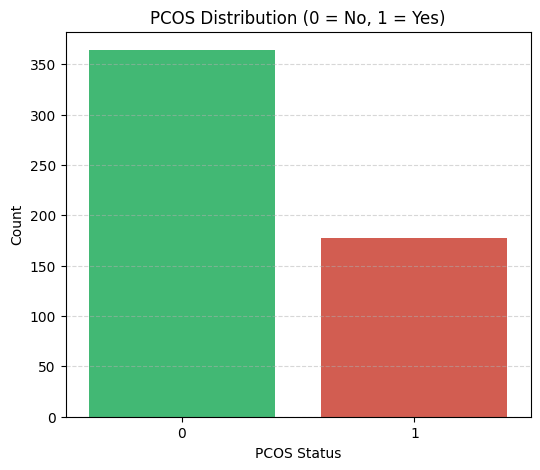


Percentage Distribution of PCOS:
 PCOS (Y/N)
0    67.28281
1    32.71719
Name: proportion, dtype: float64


In [ ]:
# 🎯 PCOS distribution
plt.figure(figsize=(6,5))
sns.countplot(x='PCOS (Y/N)', data=df, palette=['#2ecc71','#e74c3c'])
plt.title("PCOS Distribution (0 = No, 1 = Yes)")
plt.xlabel("PCOS Status")
plt.ylabel("Count")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# Calculate % distribution
pcos_counts = df['PCOS (Y/N)'].value_counts(normalize=True)*100
print("\nPercentage Distribution of PCOS:\n", pcos_counts)


## Visualize numeric columns

In [1]:

num_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
num_cols = [col for col in num_cols if col not in ['PCOS(Y/N)']]

for col in num_cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, color='skyblue')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.grid(linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.show()


NameError: name 'df' is not defined

In [ ]:
print(df.columns.tolist())


['Patient File No.', 'Stress_Level', ' Age', 'Weight', 'Height', 'BMI', 'Pulse rate(bpm) ', 'RR (breaths/min)', 'Hb(g/dl)', 'Family_History_PCOS', 'Thyroid', 'Cycle(R/I)', 'menstrual length(days)', 'Smoking', 'Hip(inch)', 'Waist(inch)', 'Waist:Hip Ratio', 'WeightGain(Y/N)', 'Hormonal_Imbalance', 'Skin darkening (Y/N)', 'sleep Hours', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)', 'Hair loss(Y/N)', 'Marital_Status', 'Length_of_cycle', 'hair growth(Y/N)', 'PCOS (Y/N)']


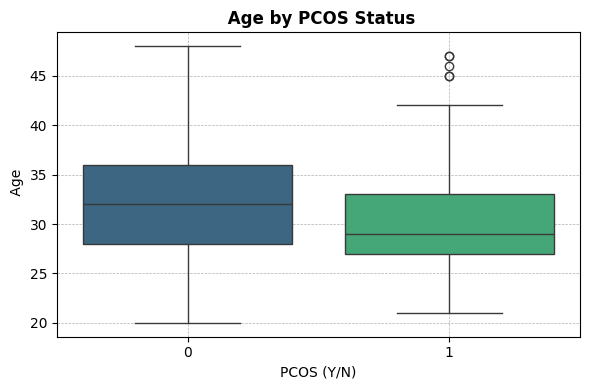

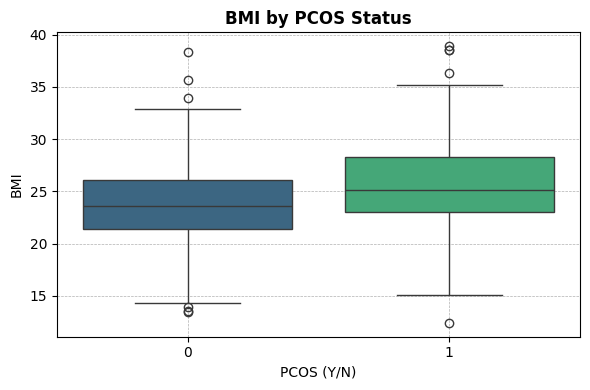

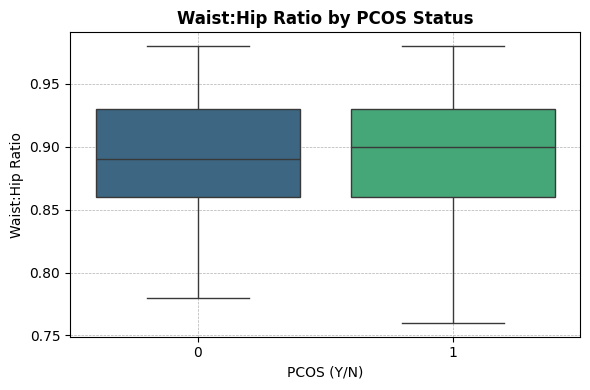

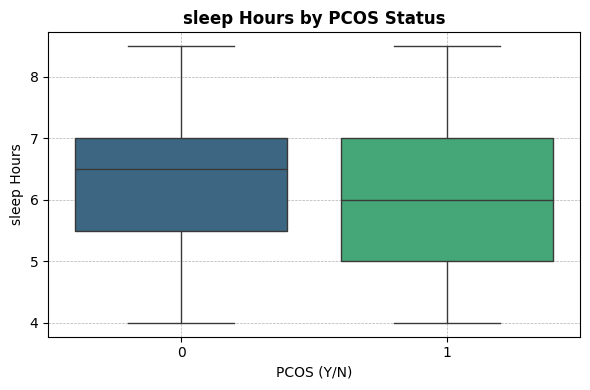

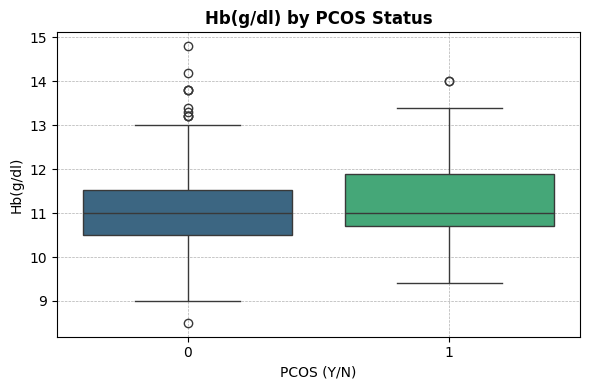

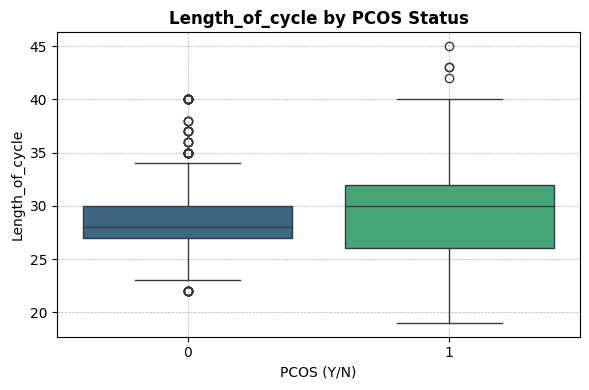

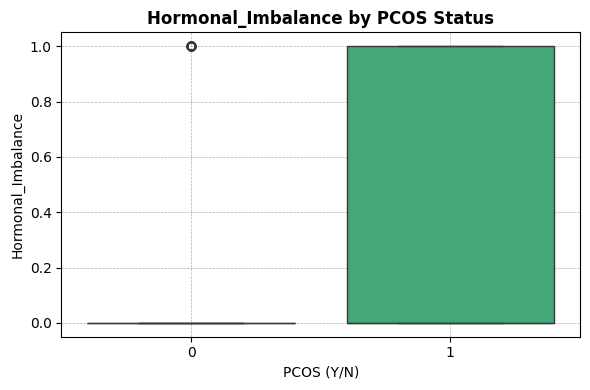

In [ ]:
# ⚖️ Compare distributions for key numeric features across PCOS Status
key_features = [
    ' Age','BMI','Waist:Hip Ratio','sleep Hours','Hb(g/dl)',
    'Length_of_cycle','Hormonal_Imbalance'
]

for feature in key_features:
    if feature in df.columns:   # ✅ safety check — only plot if column exists
        plt.figure(figsize=(6,4))
        sns.boxplot(x='PCOS (Y/N)', y=feature, data=df, palette='viridis')
        plt.title(f"{feature} by PCOS Status", fontsize=12, fontweight='bold')
        plt.xlabel("PCOS (Y/N)")
        plt.ylabel(feature)
        plt.grid(linestyle='--', linewidth=0.5)
        plt.tight_layout()
        plt.show()
    else:
        print(f"⚠️ Skipped {feature} — not found in dataset!")


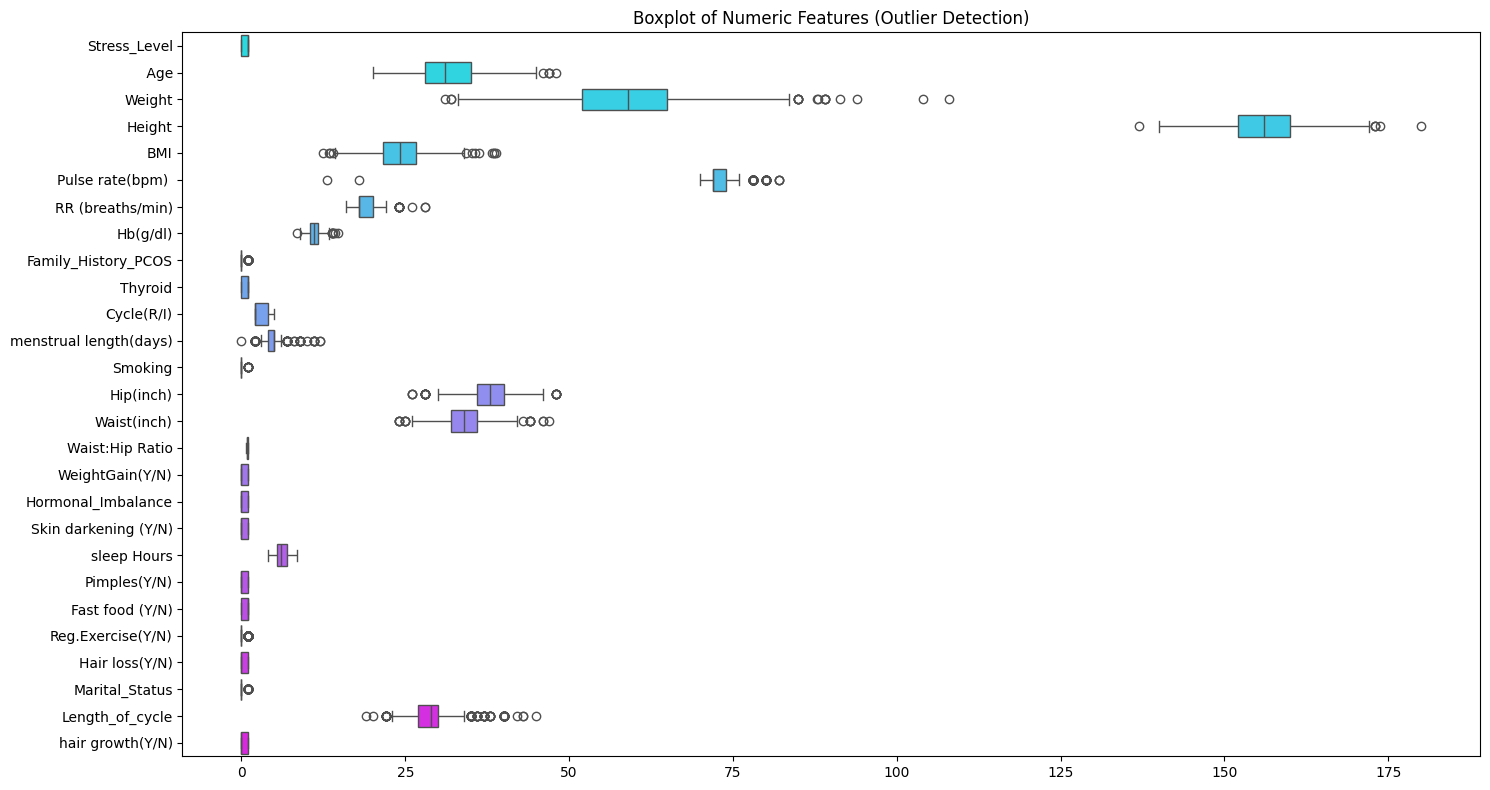

In [ ]:
# 📦 Outlier detection
plt.figure(figsize=(15,8))
sns.boxplot(data=df[num_cols], orient='h', palette='cool')
plt.title("Boxplot of Numeric Features (Outlier Detection)")
plt.tight_layout()
plt.show()


## Train-Test Split

In [ ]:


from sklearn.model_selection import train_test_split

# ✅ Separate features (X) and target (y)
X = df.drop('PCOS (Y/N)', axis=1)
y = df['PCOS (Y/N)']

# ✅ Split the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y   # keeps same PCOS ratio in both sets
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)
print("✅ Data successfully split into Train & Test")


Training shape: (432, 28)
Testing shape : (109, 28)
✅ Data successfully split into Train & Test


In [ ]:
# 🎯 STEP 4.2 - Handle Missing Values + Encode Categorical Data

from sklearn.preprocessing import LabelEncoder

# 🔹 1. Check for missing values
print("Missing values before cleaning:")
print(X_train.isnull().sum().sum(), "missing values total")

# If any missing numeric values exist → fill with median
X_train = X_train.fillna(X_train.median(numeric_only=True))
X_test = X_test.fillna(X_test.median(numeric_only=True))

# 🔹 2. Identify categorical columns
categorical_cols = X_train.select_dtypes(include='object').columns
print("\nCategorical columns found:", categorical_cols.tolist())

# 🔹 3. Encode categorical data (like Yes/No, Married/Unmarried)
encoder = LabelEncoder()
for col in categorical_cols:
    X_train[col] = encoder.fit_transform(X_train[col].astype(str))
    X_test[col] = encoder.transform(X_test[col].astype(str))

print("\n✅ Encoding done! Now all features are numeric and model-ready.")
print("Training data types:\n", X_train.dtypes.head())


Missing values before cleaning:
1 missing values total

Categorical columns found: []

✅ Encoding done! Now all features are numeric and model-ready.
Training data types:
 Patient File No.      int64
Stress_Level          int64
 Age                  int64
Weight              float64
Height              float64
dtype: object


In [ ]:
# 🎯 STEP 4.3 - Feature Scaling (Standardization)

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit on training data and transform both train & test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Feature Scaling done!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)


✅ Feature Scaling done!
Scaled training data shape: (432, 28)
Scaled testing data shape: (109, 28)


## Handle Class Imbalance using SMOTE

In [ ]:
# 🎯 STEP 4.4 - Handle Class Imbalance using SMOTE

from imblearn.over_sampling import SMOTE
from collections import Counter

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply on scaled training data
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# Show before and after balancing
print("Before SMOTE:", Counter(y_train))
print("After SMOTE :", Counter(y_train_smote))


Before SMOTE: Counter({0: 291, 1: 141})
After SMOTE : Counter({0: 291, 1: 291})


In [ ]:
LogisticRegression(class_weight='balanced')
RandomForestClassifier(class_weight='balanced')


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Feature Selection using Boruta

In [ ]:
# 🎯 STEP 5 - Feature Selection using Boruta

from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Initialize Random Forest (Boruta needs it as base estimator)
rf = RandomForestClassifier(n_jobs=-1, class_weight='balanced', random_state=42)

# Initialize Boruta feature selector
boruta = BorutaPy(
    estimator=rf,
    n_estimators='auto',
    max_iter=100,      # number of iterations for stability
    random_state=42
)

# Fit Boruta on training data (SMOTE-balanced)
boruta.fit(np.array(X_train_smote), np.array(y_train_smote))

# ✅ Print selected features
selected_features = X.columns[boruta.support_].tolist()
print("\n⭐ Selected Features by Boruta:")
for f in selected_features:
    print("  -", f)

# Show how many features were chosen
print(f"\n✅ Total Selected Features: {len(selected_features)} out of {X.shape[1]}")



⭐ Selected Features by Boruta:
  - Patient File No.
  -  Age
  - Weight
  - BMI
  - Cycle(R/I)
  - menstrual length(days)
  - Waist:Hip Ratio
  - WeightGain(Y/N)
  - Hormonal_Imbalance
  - Skin darkening (Y/N)
  - Pimples(Y/N)
  - Fast food (Y/N)
  - hair growth(Y/N)

✅ Total Selected Features: 13 out of 28


In [ ]:
# 🎯 STEP 5 - Feature Selection using Boruta

from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Initialize Random Forest (Boruta needs it as base estimator)
rf = RandomForestClassifier(n_jobs=-1, class_weight='balanced', random_state=42)

# Initialize Boruta feature selector
boruta = BorutaPy(
    estimator=rf,
    n_estimators='auto',
    max_iter=100,      # number of iterations for stability
    random_state=42
)


# Fit Boruta on training data (SMOTE-balanced)
boruta.fit(np.array(X_train_smote), np.array(y_train_smote))

# ✅ Print selected features
selected_features = X.columns[boruta.support_].tolist()
print("\n⭐ Selected Features by Boruta:")
for f in selected_features:
    print("  -", f)

# Show how many features were chosen
print(f"\n✅ Total Selected Features: {len(selected_features)} out of {X.shape[1]}")



⭐ Selected Features by Boruta:
  - Patient File No.
  -  Age
  - Weight
  - BMI
  - Cycle(R/I)
  - menstrual length(days)
  - Waist:Hip Ratio
  - WeightGain(Y/N)
  - Hormonal_Imbalance
  - Skin darkening (Y/N)
  - Pimples(Y/N)
  - Fast food (Y/N)
  - hair growth(Y/N)

✅ Total Selected Features: 13 out of 28


## Model Training & Evaluation


📊 Logistic Regression Evaluation Results
Accuracy: 0.8716
              precision    recall  f1-score   support

           0       0.94      0.86      0.90        73
           1       0.76      0.89      0.82        36

    accuracy                           0.87       109
   macro avg       0.85      0.88      0.86       109
weighted avg       0.88      0.87      0.87       109



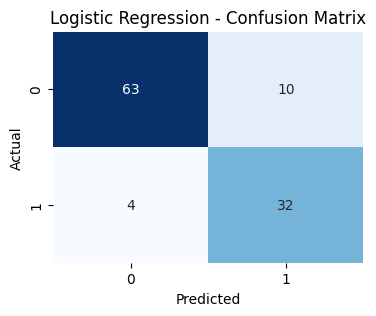


📊 Random Forest Evaluation Results
Accuracy: 0.8716
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        73
           1       0.81      0.81      0.81        36

    accuracy                           0.87       109
   macro avg       0.85      0.85      0.85       109
weighted avg       0.87      0.87      0.87       109



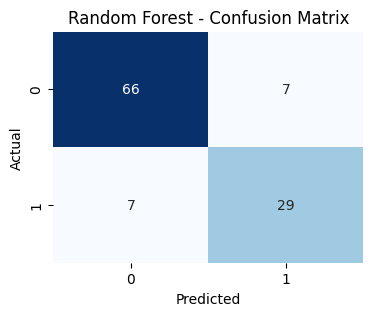


📊 XGBoost Evaluation Results
Accuracy: 0.8532
              precision    recall  f1-score   support

           0       0.91      0.86      0.89        73
           1       0.75      0.83      0.79        36

    accuracy                           0.85       109
   macro avg       0.83      0.85      0.84       109
weighted avg       0.86      0.85      0.86       109



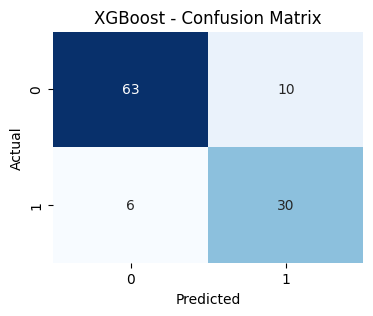

In [ ]:
# 🎯 STEP 6 - Model Training & Evaluation

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
# 🔹 Use Boruta-selected features (dropping 'Patient File No.' since it’s just an ID)
selected_features = [
     'Weight', 'BMI', 'Cycle(R/I)', 'menstrual length(days)',
    'Waist:Hip Ratio', 'WeightGain(Y/N)', 'Hormonal_Imbalance',
    'Skin darkening (Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'hair growth(Y/N)'
]

# Training and test data with only selected features
X_train_fs = pd.DataFrame(X_train_smote, columns=X.columns)[selected_features]
X_test_fs = pd.DataFrame(X_test_scaled, columns=X.columns)[selected_features]
models = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
}
for name, model in models.items():
    model.fit(X_train_fs, y_train_smote)
    y_pred = model.predict(X_test_fs)

    print(f"\n{'='*70}")
    print(f"📊 {name} Evaluation Results")
    print("="*70)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix Visualization
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


In [ ]:
from xgboost import XGBClassifier

xgb_tuned = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    random_state=42,
    eval_metric='logloss'
)

xgb_tuned.fit(X_train_fs, y_train_smote)
y_pred_tuned = xgb_tuned.predict(X_test_fs)

from sklearn.metrics import classification_report, accuracy_score
print("Tuned XGBoost Accuracy:", accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test, y_pred_tuned))


Tuned XGBoost Accuracy: 0.8532110091743119
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        73
           1       0.74      0.86      0.79        36

    accuracy                           0.85       109
   macro avg       0.83      0.86      0.84       109
weighted avg       0.86      0.85      0.86       109



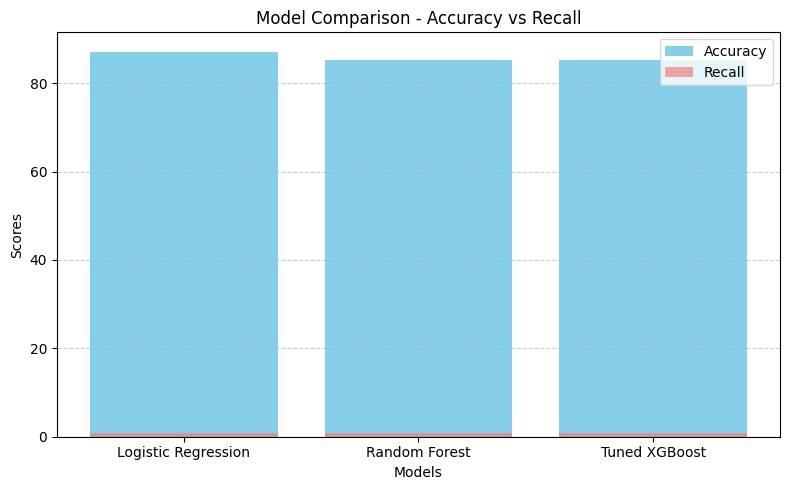

In [ ]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Random Forest', 'Tuned XGBoost']
accuracy = [87.16, 85.32, 85.32]
recall = [0.89, 0.83, 0.83]

plt.figure(figsize=(8,5))
plt.bar(models, accuracy, color='skyblue', label='Accuracy')
plt.bar(models, recall, color='lightcoral', alpha=0.7, label='Recall')
plt.xlabel('Models')
plt.ylabel('Scores')
plt.title('Model Comparison - Accuracy vs Recall')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
